# Evasão × sucesso: as 4 variações

|            | **Leiden** (que perfis existem?) | **GNN GraphSAGE** (a vizinhança ajuda a prever?) |
|------------|------------------------|-------------------------------|
| **Gower**      | variação 1 | variação 2 |
| **Associação** | variação 3 | variação 4 |

O pipeline é um só. Entre as variações muda **só a distância** (linha) e **o método** (coluna). Todo o resto é igual nas quatro: dados, janelas, k, grafo e avaliação.

- **Dados:** UCI 697, só **Dropout × Graduate** (3.630 alunos). Os *Enrolled* ficam fora porque ainda não têm desfecho.
- **Grafo:** cada aluno é um vértice. A aresta i–j existe se um está entre os `K` mais parecidos do outro, nos dois sentidos (kNN mútuo). O desfecho **nunca** entra no grafo.
- **Janelas (Regra 1):** cada análise usa só o que já se sabia naquele momento.

In [1]:
# %pip install gower igraph leidenalg torch torch_geometric scikit-learn pandas matplotlib
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import gower, igraph as ig, leidenalg as la
import torch, torch.nn.functional as F
from torch_geometric.nn.models import GraphSAGE, MLP
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score, normalized_mutual_info_score as NMI
from scipy.stats import chi2_contingency

# ===== PARÂMETROS (iguais para as 4 variações) =====
K = 40                                     # vizinhos do kNN mútuo
JANELAS_RODAR = ["1_matricula", "3_fim_1sem"]
N_PERM = 1000                              # permutações do teste do Leiden
DOBRAS = 5                                 # validação cruzada da GNN
SEED = 42
torch.use_deterministic_algorithms(True); torch.set_num_threads(1)   # GNN reprodutível na mesma máquina

# ===== FIGURAS (só desenho) =====
LARGURA = 6.3                              # pol.: largura útil de A4 com margens de 2,5 cm
plt.rcParams.update({"font.size": 9, "axes.titlesize": 9, "axes.labelsize": 9, "xtick.labelsize": 9,
                     "ytick.labelsize": 9, "legend.fontsize": 9, "figure.titlesize": 9, "pdf.fonttype": 42})
COR_EVADIU, COR_FORMOU = "#c0392b", "#27ae60"
CORES_M = {"GraphSAGE": "#534AB7", "MLP (sem arestas)": "#B4B2A9", "Logística": "#5F5E5A"}

## 1. Dados e janelas

In [2]:
df = pd.read_csv("data.csv", sep=";")
NOMES = ["marital","app_mode","app_order","course","shift","prev_qual","prev_grade","nationality",
         "mother_qual","father_qual","mother_occ","father_occ","admission_grade","displaced",
         "special_needs","debtor","tuition_ok","gender","scholarship","age","international",
         "s1_credited","s1_enrolled","s1_evaluations","s1_approved","s1_grade","s1_without_eval",
         "s2_credited","s2_enrolled","s2_evaluations","s2_approved","s2_grade","s2_without_eval",
         "unemployment","inflation","gdp","target"]
df.columns = NOMES
df = df[df.target != "Enrolled"].reset_index(drop=True)      # 2 classes
y = (df.pop("target") == "Dropout").astype(int).values       # 1 = evadiu, 0 = formou
N = len(df)
print(f"{N} alunos | evasão geral = {y.mean():.1%}")

CAT_BASE = ["marital","app_mode","shift","prev_qual","nationality","mother_qual","father_qual",
            "mother_occ","father_occ","displaced","special_needs","gender","international"]
NUM_BASE = ["app_order","prev_grade","admission_grade","age"]
CAT_FIN  = CAT_BASE + ["debtor","tuition_ok","scholarship"]
NUM_S1   = ["s1_credited","s1_enrolled","s1_evaluations","s1_approved","s1_grade","s1_without_eval"]
NUM_S2   = [c.replace("s1_", "s2_") for c in NUM_S1]
JANELAS = {                                    # (categóricas, numéricas)
    "1_matricula":  (CAT_BASE, NUM_BASE),
    "2_financeiro": (CAT_FIN,  NUM_BASE),
    "3_fim_1sem":   (CAT_FIN,  NUM_BASE + NUM_S1),
    "4_fim_2sem":   (CAT_FIN,  NUM_BASE + NUM_S1 + NUM_S2),
}
# curso e macroeconomia ficam fora da distância; categorias com < 30 alunos viram "outros" (-1)
for c in CAT_FIN:
    vc = df[c].value_counts()
    df[c] = df[c].where(df[c].isin(vc[vc >= 30].index), -1)

3630 alunos | evasão geral = 39.1%


## 2. As duas distâncias (a variável das linhas)

- **Gower** (lib `gower`): numéricas entram como |a−b|/amplitude e categóricas como 0 (iguais) ou 1 (diferentes). Todas as variáveis têm o mesmo peso.
- **Associação** (preset `u_dep` do pacote R `manydist`): duas categorias da mesma variável ficam próximas se quem tem uma *se parece* com quem tem a outra nas demais variáveis. As numéricas são padronizadas e rotacionadas por PCA, e cada variável é dividida pela sua distância média. Como não existe lib Python, usamos a reimplementação do grupo, conferida contra o `manydist` 0.5.1 (correlação 1,000 em 500 alunos).

In [3]:
def dist_gower(cats, nums):
    X = pd.concat([df[cats].astype(str), df[nums].astype(float)], axis=1)
    return gower.gower_matrix(X, cat_features=[True] * len(cats) + [False] * len(nums))

def dist_associacao(cats, nums):
    D = np.zeros((N, N))
    # categóricas: perfil de cada categoria nas outras variáveis -> TVD entre perfis
    codes = [pd.Categorical(df[c]).codes for c in cats]
    Q = [c.max() + 1 for c in codes]; pos = np.cumsum([0] + Q); m = len(cats)
    Z = np.zeros((N, sum(Q)))
    for j, c in enumerate(codes): Z[np.arange(N), pos[j] + c] = 1
    ZZ = Z.T @ Z; np.fill_diagonal(ZZ, 0)
    P = ZZ / np.maximum(Z.sum(0)[:, None], 1)
    for j, c in enumerate(codes):
        Pj = P[pos[j]:pos[j + 1]]
        delta = np.abs(Pj[:, None, :] - Pj[None, :, :]).sum(-1) / (2 * (m - 1))
        f = np.bincount(c, minlength=Q[j]) / N
        media = f @ delta @ f
        if media > 0: D += delta[c[:, None], c[None, :]] / media      # comensurável
    # numéricas: padroniza + PCA completo, cada componente dividido pela sua distância média
    X = df[nums].to_numpy(float); X = (X - X.mean(0)) / X.std(0, ddof=1)
    X = X @ np.linalg.svd(X, full_matrices=False)[2].T
    for k in range(X.shape[1]):
        dk = np.abs(X[:, k, None] - X[None, :, k]); D += dk / dk.mean()
    return D.astype(np.float32)

DISTANCIAS = {"Gower": dist_gower, "Associação": dist_associacao}

## 3. Grafo: kNN mútuo (igual para as duas distâncias)
Peso da aresta = semelhança = 1 − d / d_max. A divisão por d_max serve porque a distância por associação não fica entre 0 e 1.

In [4]:
def knn_mutuo(D, k=K):
    Dm = np.round(D, 6); np.fill_diagonal(Dm, np.inf)       # arredonda: empates exatos em qualquer máquina
    viz = np.argsort(Dm, axis=1, kind="stable")[:, :k]    # empate desfeito pelo índice do aluno
    A = np.zeros((N, N), bool); A[np.repeat(np.arange(N), k), viz.ravel()] = True
    i, j = np.where(np.triu(A & A.T, 1))
    return i, j, np.maximum(1 - D[i, j] / D.max(), 1e-3)

## 4. Os dois métodos (a variável das colunas)

**Leiden:** encontra comunidades sem olhar o desfecho. Depois perguntamos se as comunidades têm taxas de evasão diferentes, usando o **V de Cramér** entre comunidade e desfecho. Para saber se isso é real ou acaso, comparamos com `N_PERM` embaralhamentos do desfecho, mantendo o grafo fixo. Na análise só entram comunidades com pelo menos 30 alunos.

**GNN:** GraphSAGE (2 camadas, `torch_geometric`) contra um **MLP com a mesma arquitetura e sem arestas**. A diferença entre os dois responde se a vizinhança ajuda. A regressão logística entra como referência. Usamos validação cruzada estratificada com 5 dobras, e o rótulo da dobra de teste fica escondido. O grafo e os atributos de todos os alunos são visíveis (modo transdutivo, padrão em classificação de nós), mas nenhum rótulo de teste entra no treino.

In [5]:
def cramer_v(memb, yy):
    T = pd.crosstab(memb, yy).values
    return np.sqrt(chi2_contingency(T, correction=False)[0] / (T.sum() * (min(T.shape) - 1)))

def roda_leiden(i, j, w):
    g = ig.Graph(n=N, edges=list(zip(i, j))); g.es["weight"] = w
    part = la.find_partition(g, la.ModularityVertexPartition, weights="weight", seed=0)
    memb = np.array(part.membership)
    grandes = np.isin(memb, np.where(np.bincount(memb) >= 30)[0])     # comunidades >= 30 alunos
    mm, yy = memb[grandes], y[grandes]
    v = cramer_v(mm, yy)
    rs = np.random.default_rng(SEED)
    nulo = np.array([cramer_v(mm, rs.permutation(yy)) for _ in range(N_PERM)])
    comp = (pd.DataFrame({"comunidade": mm, "evadiu": yy}).groupby("comunidade")
              .agg(alunos=("evadiu", "size"), evasao=("evadiu", "mean"))
              .sort_values("evasao", ascending=False))
    return dict(memb=memb, comp=comp, modularidade=part.modularity, comunidades=len(comp),
                cobertura=grandes.mean(), V=v, V_max_nulo=nulo.max(),
                p=(1 + (nulo >= v).sum()) / (1 + N_PERM), NMI=NMI(mm, yy))

In [6]:
def atributos(cats, nums):
    oh = pd.get_dummies(df[cats].astype(str), dtype=np.float32).values
    num = df[nums].to_numpy(np.float32); num = (num - num.mean(0)) / num.std(0)
    return torch.tensor(np.hstack([oh, num]))

def treina(model, X, ei, tr, va, epocas=300, paciencia=30):
    yt = torch.tensor(y)
    peso = torch.tensor(len(tr) / (2 * np.bincount(y[tr])), dtype=torch.float32)   # compensa 39% evadiu x 61% formou
    opt = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    melhor, estado, sem = -1, None, 0
    for _ in range(epocas):
        model.train(); opt.zero_grad()
        F.cross_entropy(model(X, ei)[tr], yt[tr], weight=peso).backward(); opt.step()
        model.eval()
        with torch.no_grad(): f = f1_score(y[va], model(X, ei)[va].argmax(1), average="macro")
        if f > melhor: melhor, estado, sem = f, {k: v.clone() for k, v in model.state_dict().items()}, 0
        elif (sem := sem + 1) >= paciencia: break
    model.load_state_dict(estado); model.eval()
    with torch.no_grad(): return F.softmax(model(X, ei), 1)[:, 1].numpy()     # P(evadiu)

class SemArestas(torch.nn.Module):          # MLP do PyG com a mesma assinatura da GNN
    def __init__(self, d): super().__init__(); self.m = MLP(in_channels=d, hidden_channels=64, out_channels=2, num_layers=2, dropout=0.5, norm=None)
    def forward(self, x, ei): return self.m(x)

def roda_gnn(i, j, cats, nums):
    X = atributos(cats, nums)
    ei = torch.tensor(np.vstack([np.r_[i, j], np.r_[j, i]]), dtype=torch.long)
    linhas, oof = [], {"GraphSAGE": np.zeros(N), "MLP (sem arestas)": np.zeros(N)}
    for f, (trv, te) in enumerate(StratifiedKFold(DOBRAS, shuffle=True, random_state=SEED).split(X, y)):
        tr, va = train_test_split(trv, test_size=0.15, stratify=y[trv], random_state=f)
        modelos = {"GraphSAGE": GraphSAGE(X.shape[1], 64, num_layers=2, out_channels=2, dropout=0.5),
                   "MLP (sem arestas)": SemArestas(X.shape[1])}
        for nome, mod in modelos.items():
            torch.manual_seed(f); p = treina(mod, X, ei, tr, va); oof[nome][te] = p[te]
            linhas.append(dict(modelo=nome, dobra=f, F1=f1_score(y[te], p[te] > .5, average="macro"), AUC=roc_auc_score(y[te], p[te])))
        Xn = X.numpy(); lr = LogisticRegression(max_iter=3000, class_weight="balanced").fit(Xn[trv], y[trv])
        p = lr.predict_proba(Xn[te])[:, 1]
        linhas.append(dict(modelo="Logística", dobra=f, F1=f1_score(y[te], p > .5, average="macro"), AUC=roc_auc_score(y[te], p)))
    return pd.DataFrame(linhas), oof              # oof = P(evadiu) de cada aluno, prevista sem ele no treino

## 5. Execução das 4 variações
Roda as quatro combinações nas duas janelas e salva os números em `resultados/`. Sem figuras aqui.

In [7]:
RES = {}
for jan in JANELAS_RODAR:
    cats, nums = JANELAS[jan]
    for dist, fn in DISTANCIAS.items():
        D = fn(cats, nums); i, j, w = knn_mutuo(D); RES[jan, dist, "arestas"] = (i, j, w)
        isolados = N - len(np.unique(np.r_[i, j]))
        RES[jan, dist, "Leiden"] = roda_leiden(i, j, w)
        RES[jan, dist, "GNN"], RES[jan, dist, "oof"] = roda_gnn(i, j, cats, nums)
        v = RES[jan, dist, "Leiden"]["V"]; t = RES[jan, dist, "GNN"]
        f1 = t[t.modelo == "GraphSAGE"].F1.mean()
        print(f"{jan:12s} {dist:10s} | arestas={len(i):6d} isolados={isolados:3d} | Leiden V={v:.3f} | F1 GNN={f1:.3f}")

1_matricula  Gower      | arestas= 39980 isolados=  3 | Leiden V=0.316 | F1 GNN=0.678


1_matricula  Associação | arestas= 41742 isolados= 13 | Leiden V=0.332 | F1 GNN=0.671


3_fim_1sem   Gower      | arestas= 37318 isolados=  6 | Leiden V=0.463 | F1 GNN=0.859


3_fim_1sem   Associação | arestas= 36564 isolados= 30 | Leiden V=0.576 | F1 GNN=0.859


In [8]:
def celula_leiden(r): return f"V={r['V']:.2f} (nulo ≤{r['V_max_nulo']:.2f}, p={r['p']:.3f}) · {r['comunidades']} com. · evasão {r['comp'].evasao.min():.0%}–{r['comp'].evasao.max():.0%}"
def celula_gnn(t):
    w = t.pivot(index="dobra", columns="modelo", values="F1"); g = w["GraphSAGE"] - w["MLP (sem arestas)"]
    return f"F1 GNN {w['GraphSAGE'].mean():.3f} · MLP {w['MLP (sem arestas)'].mean():.3f} · Log {w['Logística'].mean():.3f} · ganho {g.mean():+.3f}±{g.std():.3f}"

for jan in JANELAS_RODAR:
    tab = pd.DataFrame({"Leiden (que perfis existem?)": {d: celula_leiden(RES[jan, d, "Leiden"]) for d in DISTANCIAS},
                        "GNN GraphSAGE (a vizinhança ajuda?)": {d: celula_gnn(RES[jan, d, "GNN"]) for d in DISTANCIAS}})
    print(f"\n=== Janela {jan} ==="); display(tab.style.set_properties(**{"white-space": "normal", "text-align": "left"}))


=== Janela 1_matricula ===


,Leiden (que perfis existem?),GNN GraphSAGE (a vizinhança ajuda?)
Gower,"V=0.32 (nulo ≤0.10, p=0.001) · 12 com. · evasão 19%–70%",F1 GNN 0.678 · MLP 0.675 · Log 0.678 · ganho +0.003±0.012
Associação,"V=0.33 (nulo ≤0.10, p=0.001) · 16 com. · evasão 19%–67%",F1 GNN 0.671 · MLP 0.682 · Log 0.678 · ganho -0.010±0.006



=== Janela 3_fim_1sem ===


,Leiden (que perfis existem?),GNN GraphSAGE (a vizinhança ajuda?)
Gower,"V=0.46 (nulo ≤0.09, p=0.001) · 11 com. · evasão 13%–83%",F1 GNN 0.859 · MLP 0.859 · Log 0.869 · ganho +0.000±0.014
Associação,"V=0.58 (nulo ≤0.12, p=0.001) · 18 com. · evasão 4%–96%",F1 GNN 0.859 · MLP 0.867 · Log 0.869 · ganho -0.008±0.012


In [9]:
# números brutos, para o relatório
leiden_tab = pd.DataFrame([{"janela": j, "distancia": d, **{k: v for k, v in r.items() if k not in ("memb", "comp")}}
                           for (j, d, m), r in RES.items() if m == "Leiden"]).round(3)
gnn_tab = (pd.concat([t.assign(janela=j, distancia=d) for (j, d, m), t in RES.items() if m == "GNN"])
             .groupby(["janela", "distancia", "modelo"])[["F1", "AUC"]].agg(["mean", "std"]).round(3))
leiden_tab.to_csv("resultados/leiden_resumo.csv", index=False); gnn_tab.to_csv("resultados/gnn_resumo.csv")
display(leiden_tab); display(gnn_tab)

,janela,distancia,modularidade,comunidades,cobertura,V,V_max_nulo,p,NMI
0,1_matricula,Gower,0.672,12,0.999,0.316,0.100,0.001,0.034
1,1_matricula,Associação,0.841,16,0.996,0.332,0.101,0.001,0.035
2,3_fim_1sem,Gower,0.644,11,0.997,0.463,0.091,0.001,0.077
3,3_fim_1sem,Associação,0.821,18,0.991,0.576,0.116,0.001,0.109


F1           AUC       
                                           mean    std   mean    std
janela      distancia  modelo                                       
1_matricula Associação GraphSAGE          0.671  0.010  0.733  0.015
                       Logística          0.678  0.021  0.736  0.016
                       MLP (sem arestas)  0.682  0.014  0.738  0.015
            Gower      GraphSAGE          0.678  0.013  0.732  0.012
                       Logística          0.678  0.021  0.736  0.016
                       MLP (sem arestas)  0.675  0.024  0.731  0.021
3_fim_1sem  Associação GraphSAGE          0.859  0.005  0.922  0.003
                       Logística          0.869  0.009  0.930  0.006
                       MLP (sem arestas)  0.867  0.015  0.929  0.006
            Gower      GraphSAGE          0.859  0.014  0.923  0.007
                       Logística          0.869  0.009  0.930  0.006
                       MLP (sem arestas)  0.859  0.020  0.926  0.008

Funções de desenho das seções 6 a 8. Só desenham: nenhum resultado muda. **Layout em bolhas** (só no desenho): cada comunidade com ≥ 30 alunos vira uma bolha de tamanho proporcional ao número de alunos, e bolhas mais ligadas entre si ficam mais perto. Dentro da bolha, os alunos se posicionam pelas próprias arestas. Os poucos alunos de comunidades com menos de 30 (< 1%) ficam fora do desenho. As mesmas posições valem para as figuras 01, 02 e 07.

In [10]:
# Funções de desenho usadas nas seções 6 a 8. Nenhuma delas muda os resultados.
import io, os, random
import matplotlib.patheffects as pe
from IPython.display import Image, Markdown, display
from matplotlib.collections import LineCollection
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter, FuncFormatter
from PIL import Image as PILImage
os.makedirs("figuras", exist_ok=True)
COR_Y = np.array([COR_FORMOU, COR_EVADIU])                 # 0 = formou, 1 = evadiu
LEG_Y = [Patch(color=COR_EVADIU, label="evadiu"), Patch(color=COR_FORMOU, label="formou")]
SLUG = {"Gower": "gower", "Associação": "associacao"}
NOME_JAN = {"1_matricula": "matrícula", "3_fim_1sem": "fim do 1º semestre"}
RISCO = plt.get_cmap("RdYlGn_r")                           # verde = pouca evasão, vermelho = muita (0 a 1)
FMT_BR = FuncFormatter(lambda v, _: f"{v:g}".replace(".", ","))   # vírgula decimal nos eixos
S_PONTO = 2                                                # tamanho dos pontos nos grafos (pt²)
POS = {}

def br(v, casas=2): return f"{v:.{casas}f}".replace(".", ",")

def salva(fig, nome):
    """PDF (pontos e arestas rasterizados, texto vetorial) + PNG 300 dpi com paleta reduzida; mostra o PNG."""
    base = f"figuras/{nome}"
    fig.savefig(base + ".pdf", dpi=300); fig.savefig(base + ".png", dpi=300); plt.close(fig)
    PILImage.open(base + ".png").convert("RGB").quantize(256, method=PILImage.Quantize.MEDIANCUT).save(base + ".png", optimize=True)
    prev = PILImage.open(base + ".png"); prev = prev.convert("RGB").resize((900, round(900 * prev.height / prev.width)), PILImage.LANCZOS)
    buf = io.BytesIO(); prev.quantize(256, method=PILImage.Quantize.MEDIANCUT).save(buf, "PNG", optimize=True)
    display(Markdown(f"`{base}.pdf`")); display(Image(data=buf.getvalue(), width=720))   # prévia leve do PNG salvo

def figura_grafo(paineis=2):
    # layout fixo (sem ajuste automático): as posições das bolhas ficam iguais em todas as figuras de grafo
    fig, axs = plt.subplots(paineis, 1, figsize=(LARGURA, 1.3 * LARGURA if paineis == 2 else 0.65 * LARGURA), squeeze=False)
    fig.subplots_adjust(left=0.01, right=0.80, bottom=0.01, top=0.96 if paineis == 2 else 0.99, hspace=0.1)
    return fig, axs[:, 0]

def posicoes(jan, dist):
    # layout em dois níveis, só para o desenho: (1) cada comunidade (>= 30 alunos) vira uma bolha, posicionada
    # pelas ligações entre comunidades; (2) dentro da bolha, os alunos se posicionam pelas arestas internas.
    # alunos de comunidades com < 30 alunos (< 1%) ficam fora do desenho (posição NaN)
    if (jan, dist) in POS: return POS[jan, dist]
    i, j, _ = RES[jan, dist, "arestas"]; r = RES[jan, dist, "Leiden"]; memb = r["memb"]
    comms = list(r["comp"].index); idx = {c: k for k, c in enumerate(comms)}; C = len(comms)
    tam = np.array([(memb == c).sum() for c in comms])
    rng = np.random.default_rng(SEED); random.seed(SEED)
    # (1) bolhas: grafo das comunidades, peso = nº de arestas entre elas
    W = np.zeros((C, C)); m = np.isin(memb[i], comms) & np.isin(memb[j], comms) & (memb[i] != memb[j])
    np.add.at(W, (np.array([idx[c] for c in memb[i][m]], int), np.array([idx[c] for c in memb[j][m]], int)), 1); W = W + W.T
    gc = ig.Graph.Weighted_Adjacency(W.tolist(), mode="undirected", loops=False)
    cen = np.array(gc.layout_fruchterman_reingold(weights="weight" if gc.ecount() else None).coords)
    cen = (cen - cen.mean(0)) / (np.abs(cen - cen.mean(0)).max() + 1e-9)
    raio = 0.22 * np.sqrt(tam / tam.max())
    for _ in range(500):                                   # empurra bolhas sobrepostas até não se tocarem
        mexeu = False
        for a in range(C):
            for b in range(a + 1, C):
                d = cen[b] - cen[a]; dist_ab = np.hypot(*d) + 1e-9; minimo = raio[a] + raio[b] + 0.04
                if dist_ab < minimo:
                    e = (minimo - dist_ab) / 2 * d / dist_ab; cen[a] -= e; cen[b] += e; mexeu = True
        if not mexeu: break
    # (2) alunos dentro de cada bolha
    pos = np.full((N, 2), np.nan)
    for k, c in enumerate(comms):
        nos = np.where(memb == c)[0]; loc = {v: t for t, v in enumerate(nos)}
        mm = (memb[i] == c) & (memb[j] == c)
        g = ig.Graph(n=len(nos), edges=[(loc[a], loc[b]) for a, b in zip(i[mm], j[mm])])
        p = np.array(g.layout_fruchterman_reingold(niter=300).coords); p -= np.median(p, 0)
        esc = np.percentile(np.hypot(p[:, 0], p[:, 1]), 95) + 1e-9
        p = p / esc; nr = np.hypot(p[:, 0], p[:, 1]); p[nr > 1] /= nr[nr > 1, None]      # cabe no círculo
        pos[nos] = cen[k] + p * raio[k]
    POS[jan, dist] = pos
    return pos

def desenha(ax, jan, dist, cores, titulo="", s=S_PONTO):
    i, j, _ = RES[jan, dist, "arestas"]; pos = posicoes(jan, dist)
    ok = ~np.isnan(pos[:, 0]); e = ok[i] & ok[j]
    ax.add_collection(LineCollection(np.stack([pos[i[e]], pos[j[e]]], 1), colors="#999999", linewidths=0.15,
                                     alpha=0.06, zorder=1, rasterized=True))
    if s: ax.scatter(pos[ok, 0], pos[ok, 1], c=np.asarray(cores)[ok], s=s, linewidths=0, zorder=2, rasterized=True)
    if titulo: ax.set_title(titulo, loc="left")
    ax.set_aspect("equal"); ax.axis("off"); ax.autoscale_view()

def rotula(ax, jan, dist, texto):
    r = RES[jan, dist, "Leiden"]; pos = posicoes(jan, dist)
    for c in r["comp"].index:
        cx, cy = pos[r["memb"] == c].mean(0)
        ax.text(cx, cy, texto(c), weight="bold", ha="center", va="center", linespacing=1.0, zorder=3,
                path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])

def barra_cor(ax, rotulo, pct=False):
    cax = ax.inset_axes([1.04, 0.15, 0.035, 0.7])
    cb = plt.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(0, 1), cmap=RISCO), cax=cax, label=rotulo)
    cb.ax.yaxis.set_major_formatter(PercentFormatter(1) if pct else FMT_BR)

## 6. Resultados do Leiden

In [11]:
evas = pd.concat([RES[j, d, "Leiden"]["comp"].evasao for j in JANELAS_RODAR for d in DISTANCIAS])
Vs = [RES[j, d, "Leiden"]["V"] for j in JANELAS_RODAR for d in DISTANCIAS]
nulo = max(RES[j, d, "Leiden"]["V_max_nulo"] for j in JANELAS_RODAR for d in DISTANCIAS)
pmax = max(RES[j, d, "Leiden"]["p"] for j in JANELAS_RODAR for d in DISTANCIAS)
display(Markdown(
    f"As comunidades do Leiden, encontradas **sem** o desfecho, têm taxas de evasão muito diferentes: "
    f"de {evas.min():.0%} a {evas.max():.0%}, contra {y.mean():.0%} no geral. O V de Cramér vai de {br(min(Vs))} "
    f"a {br(max(Vs))} nas quatro combinações (p = {br(pmax, 3)} em todas; o maior V com o desfecho embaralhado foi {br(nulo)})."))

As comunidades do Leiden, encontradas **sem** o desfecho, têm taxas de evasão muito diferentes: de 4% a 96%, contra 39% no geral. O V de Cramér vai de 0,32 a 0,58 nas quatro combinações (p = 0,001 em todas; o maior V com o desfecho embaralhado foi 0,12).

**Figura 01 — comunidades e situação real.** (a) As comunidades que o Leiden encontrou, com o número de alunos. (b) O mesmo grafo pintado por evadiu/formou. A situação real **não** entrou no grafo nem nas comunidades: se as cores de (b) coincidem com as bolhas de (a), os perfis são reais.

`figuras/01_grafo_comunidades_1_matricula_gower.pdf`

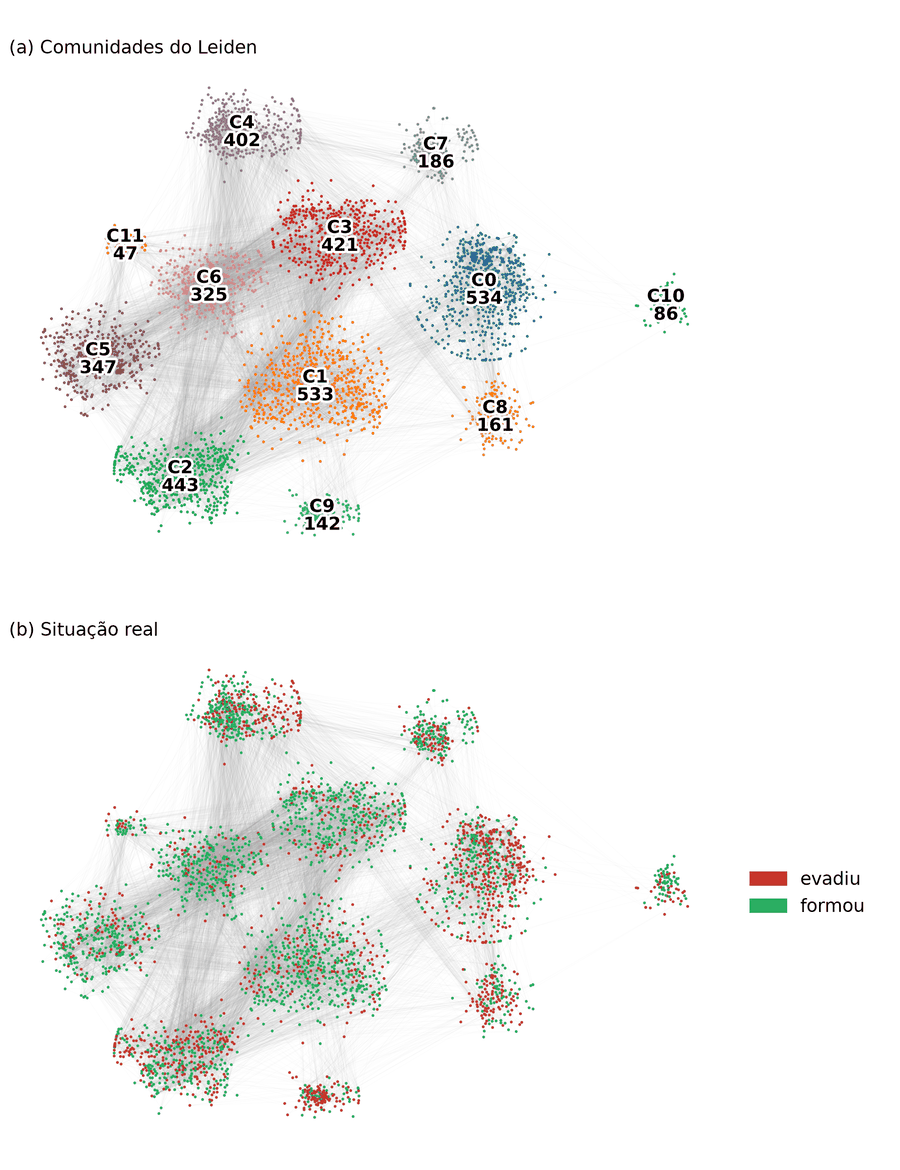

`figuras/01_grafo_comunidades_1_matricula_associacao.pdf`

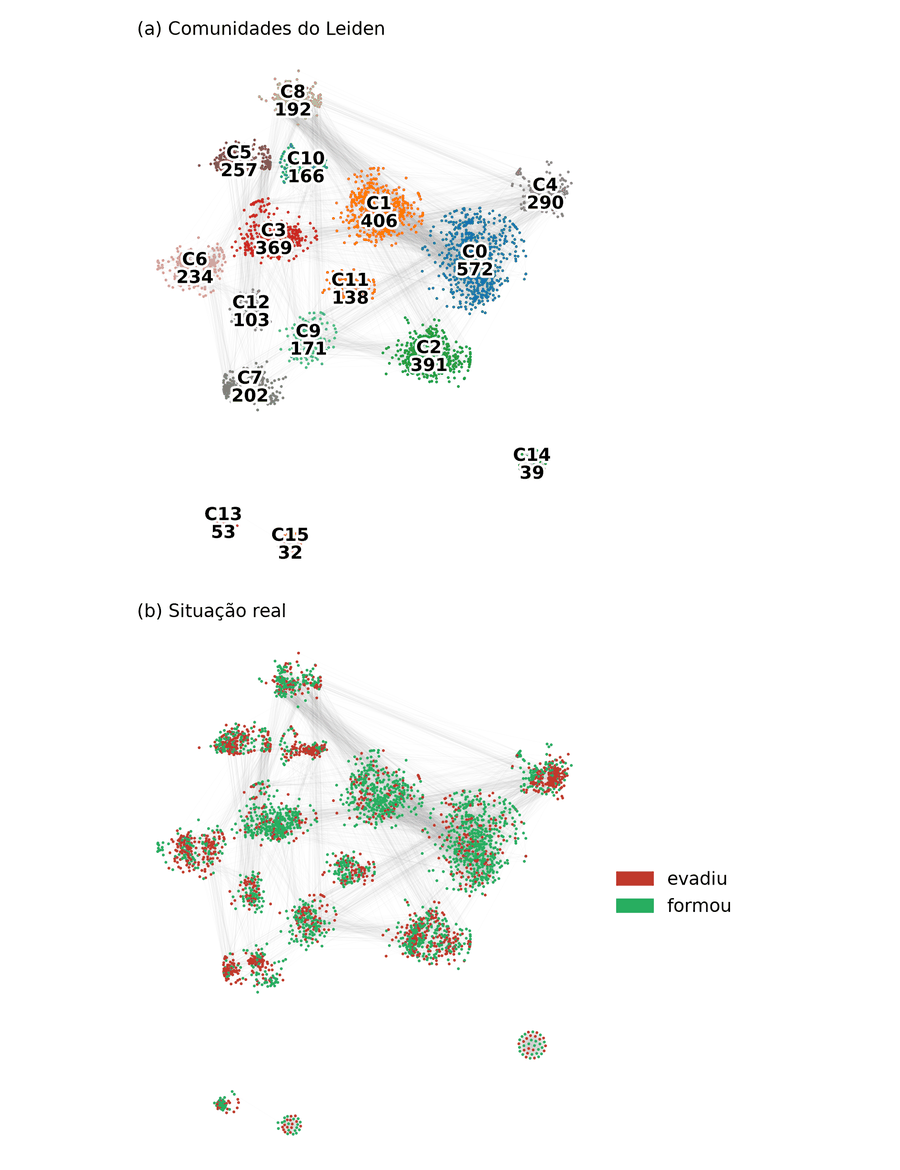

`figuras/01_grafo_comunidades_3_fim_1sem_gower.pdf`

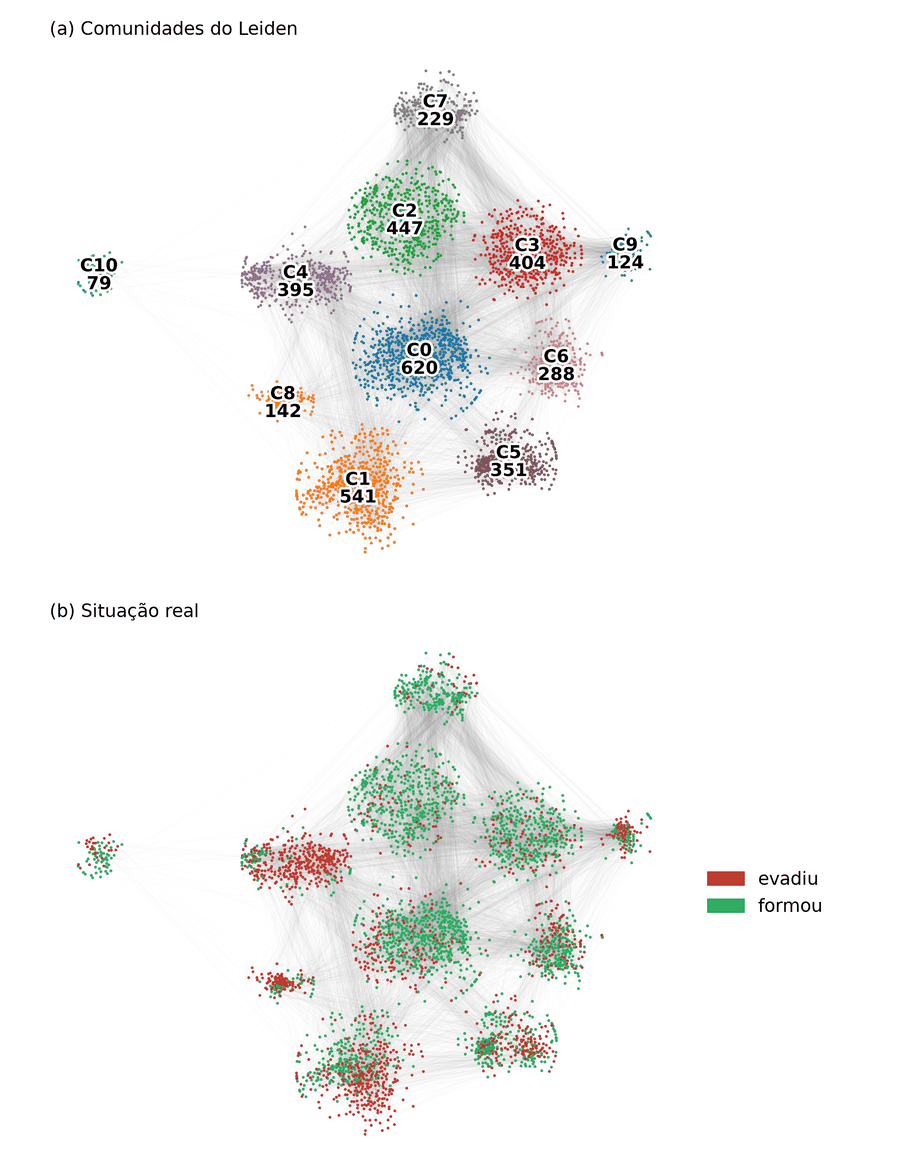

`figuras/01_grafo_comunidades_3_fim_1sem_associacao.pdf`

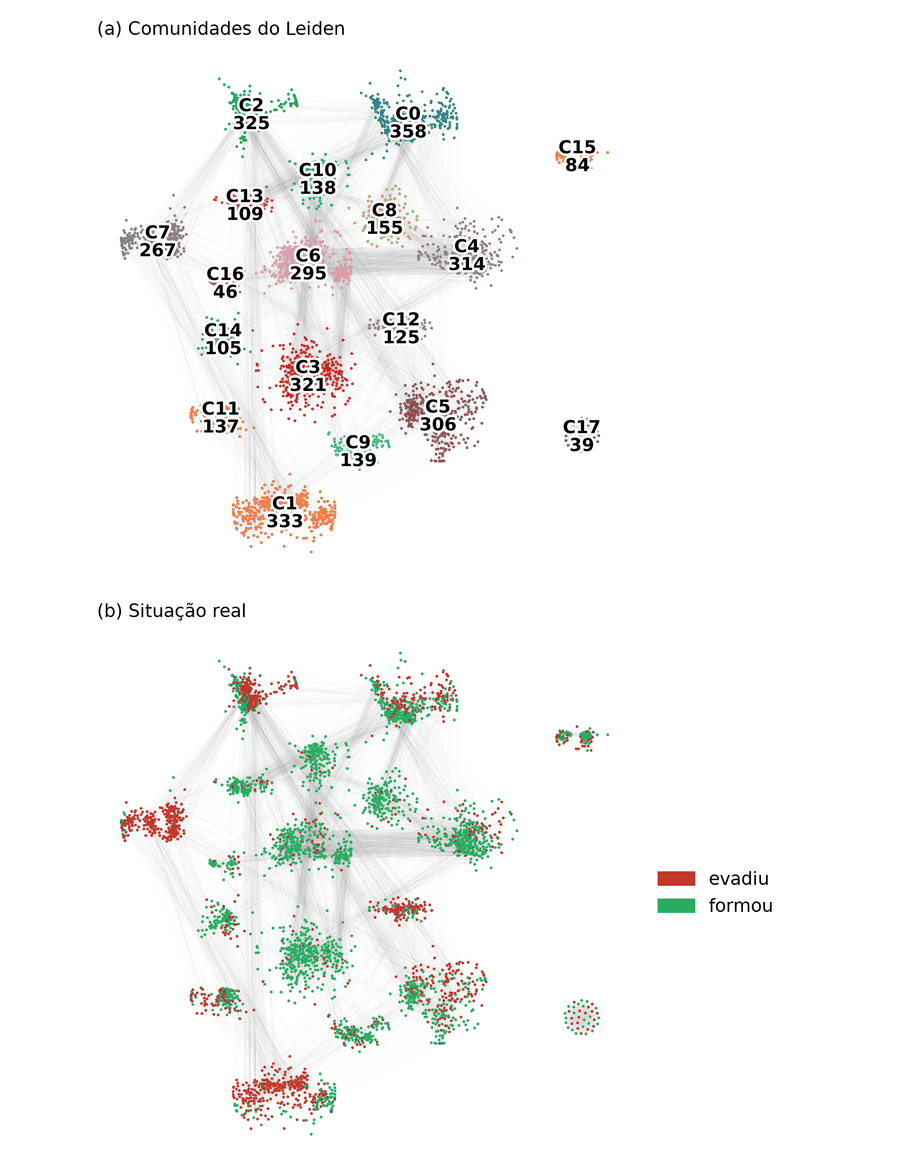

In [12]:
for jan in JANELAS_RODAR:
    for dist in DISTANCIAS:
        memb = RES[jan, dist, "Leiden"]["memb"]
        paleta = plt.get_cmap("tab10").colors + plt.get_cmap("Dark2").colors      # 18 cores fortes
        cores = np.array([paleta[c % len(paleta)] for c in memb])
        fig, (a, b) = figura_grafo()
        desenha(a, jan, dist, cores, "(a) Comunidades do Leiden")
        rotula(a, jan, dist, lambda c: f"C{c}\n{(memb == c).sum()}")
        desenha(b, jan, dist, COR_Y[y], "(b) Situação real")
        b.legend(handles=LEG_Y, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
        salva(fig, f"01_grafo_comunidades_{jan}_{SLUG[dist]}")

**Figura 02 — mapa de risco.** Cada aluno recebe a cor da taxa de evasão da sua comunidade; o rótulo é essa taxa.

`figuras/02_mapa_risco_1_matricula_gower.pdf`

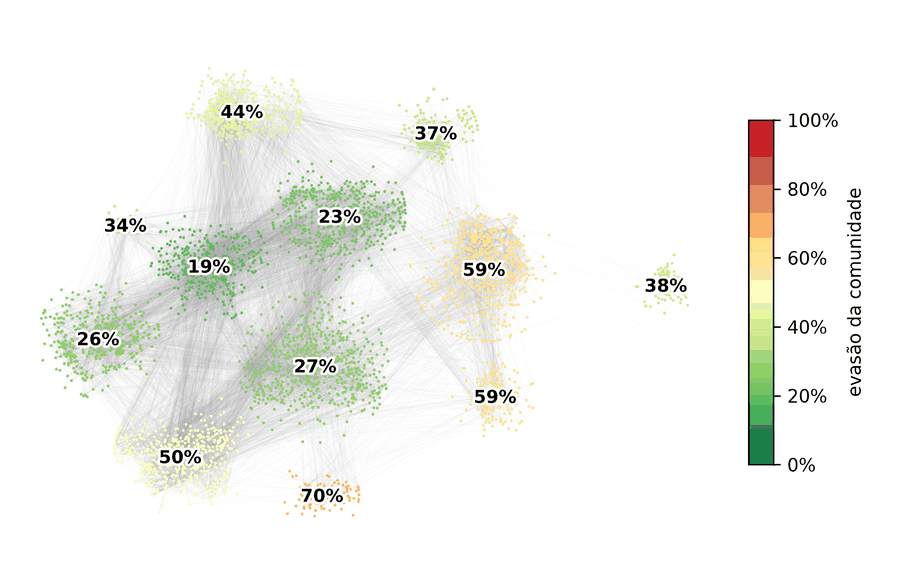

`figuras/02_mapa_risco_1_matricula_associacao.pdf`

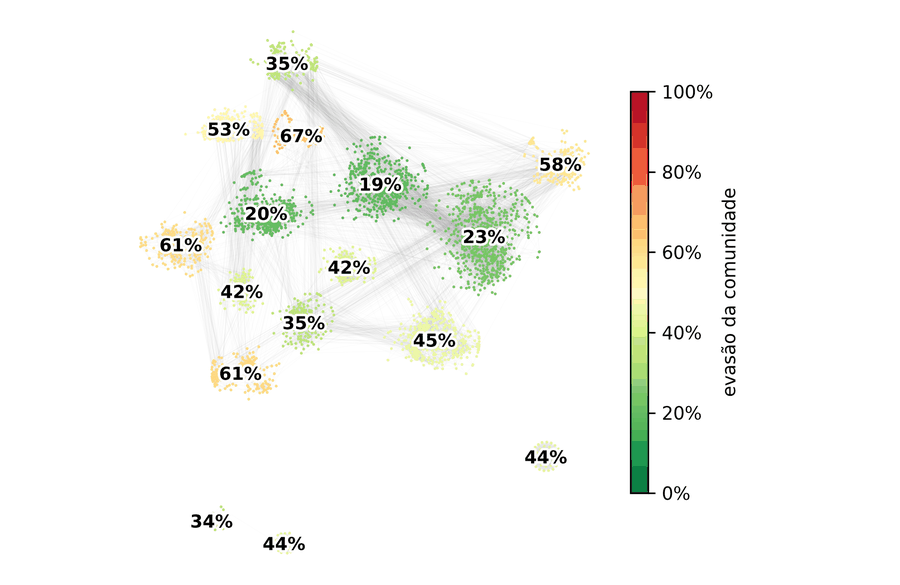

`figuras/02_mapa_risco_3_fim_1sem_gower.pdf`

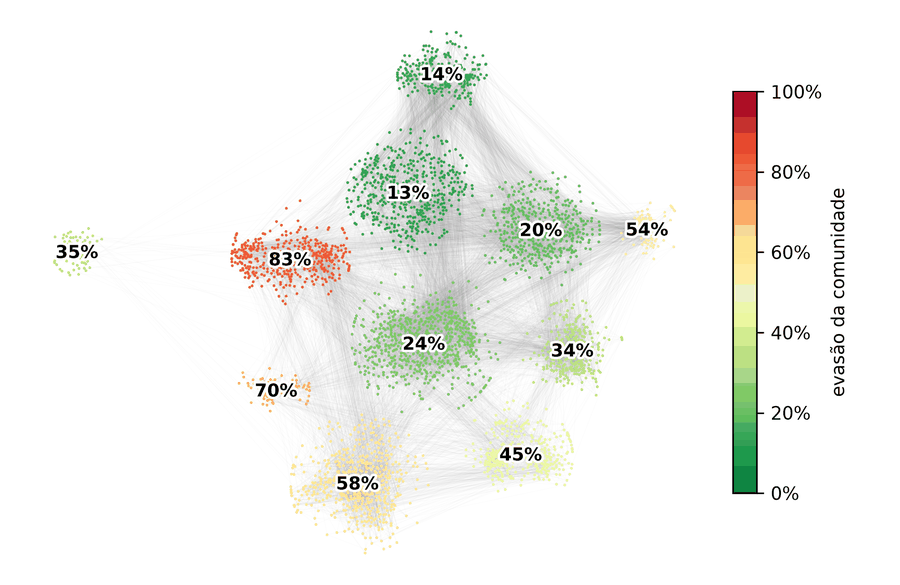

`figuras/02_mapa_risco_3_fim_1sem_associacao.pdf`

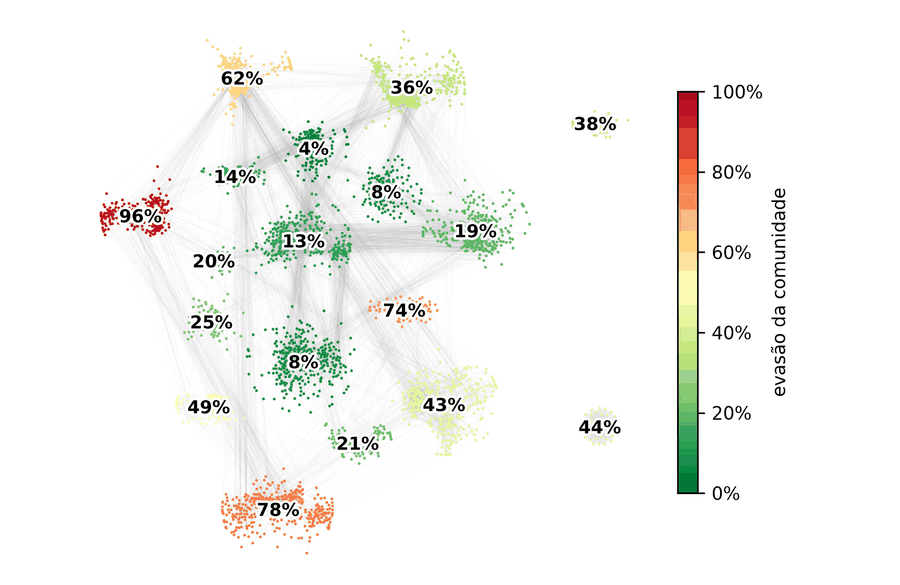

In [13]:
for jan in JANELAS_RODAR:
    for dist in DISTANCIAS:
        memb = RES[jan, dist, "Leiden"]["memb"]; taxa = pd.Series(y).groupby(memb).mean()
        fig, (ax,) = figura_grafo(1)
        desenha(ax, jan, dist, RISCO(taxa[memb].values))
        rotula(ax, jan, dist, lambda c: f"{taxa[c]:.0%}")
        barra_cor(ax, "evasão da comunidade", pct=True)
        salva(fig, f"02_mapa_risco_{jan}_{SLUG[dist]}")

**Figura 03 — composição por comunidade.** Fração de evadidos e formados em cada comunidade (≥ 30 alunos), da maior para a menor evasão. A linha pontilhada é a evasão geral.

`figuras/03_composicao_1_matricula.pdf`

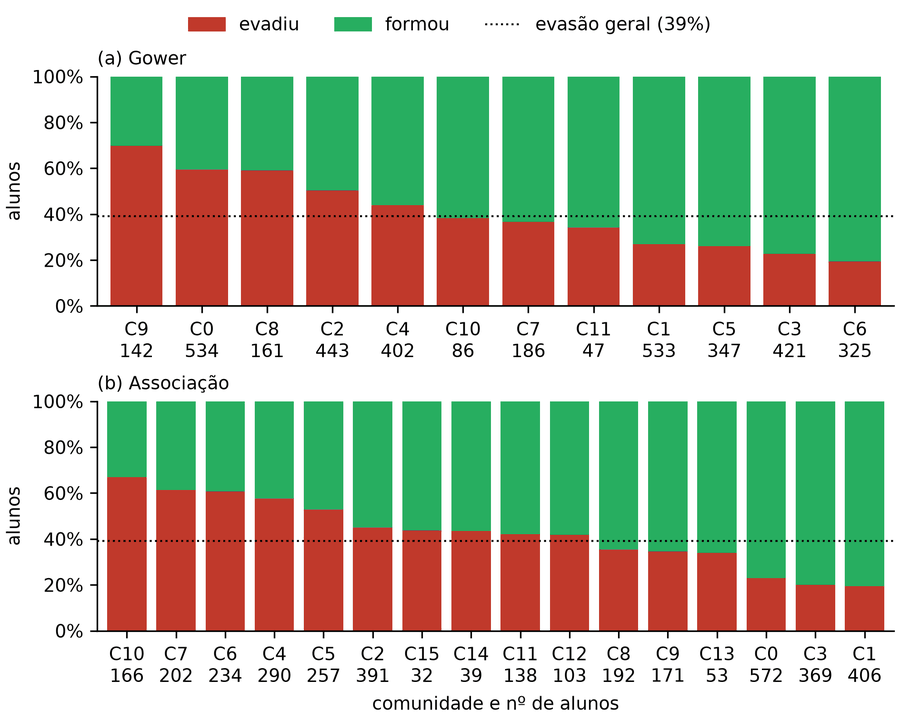

`figuras/03_composicao_3_fim_1sem.pdf`

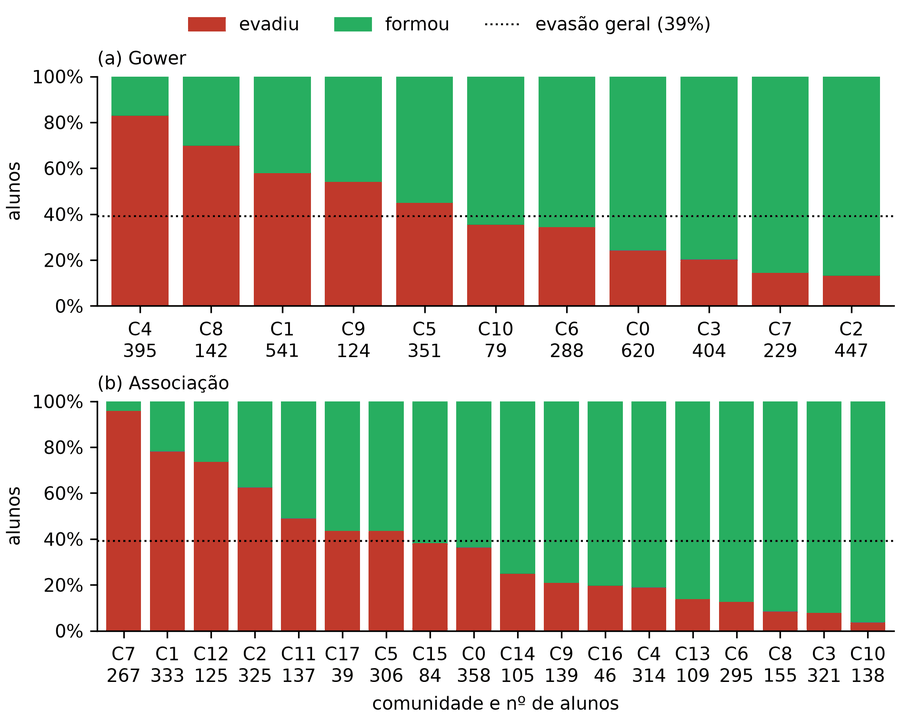

In [14]:
for jan in JANELAS_RODAR:
    fig, axs = plt.subplots(2, 1, figsize=(LARGURA, 0.8 * LARGURA), layout="constrained")
    for ax, letra, dist in zip(axs, "ab", DISTANCIAS):
        c = RES[jan, dist, "Leiden"]["comp"]; x = np.arange(len(c))
        ax.bar(x, c.evasao, color=COR_EVADIU); ax.bar(x, 1 - c.evasao, bottom=c.evasao, color=COR_FORMOU)
        ax.axhline(y.mean(), ls=":", c="k", lw=1); ax.set_ylim(0, 1); ax.set_xlim(-0.6, len(c) - 0.4)
        ax.set_xticks(x, [f"C{i}\n{n}" for i, n in zip(c.index, c.alunos)])
        ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.set_ylabel("alunos")
        ax.set_title(f"({letra}) {dist}", loc="left"); ax.spines[["top", "right"]].set_visible(False)
    axs[1].set_xlabel("comunidade e nº de alunos")
    fig.legend(handles=LEG_Y + [Line2D([], [], ls=":", c="k", lw=1, label=f"evasão geral ({y.mean():.0%})")],
               loc="outside upper center", ncols=3, frameon=False)
    salva(fig, f"03_composicao_{jan}")

**Figura 04 — perfis.** Linhas = comunidades, da maior para a menor evasão. Colunas = variáveis da janela e alguns indicadores categóricos. A cor mostra quanto a comunidade fica acima (vermelho) ou abaixo (azul) da média geral, em desvios-padrão.

`figuras/04_perfil_1_matricula_gower.pdf`

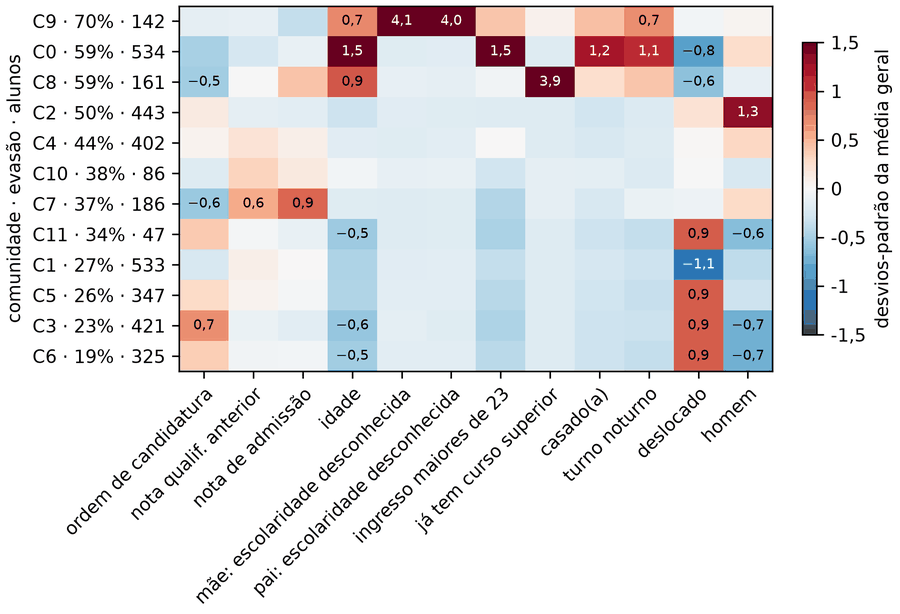

`figuras/04_perfil_1_matricula_associacao.pdf`

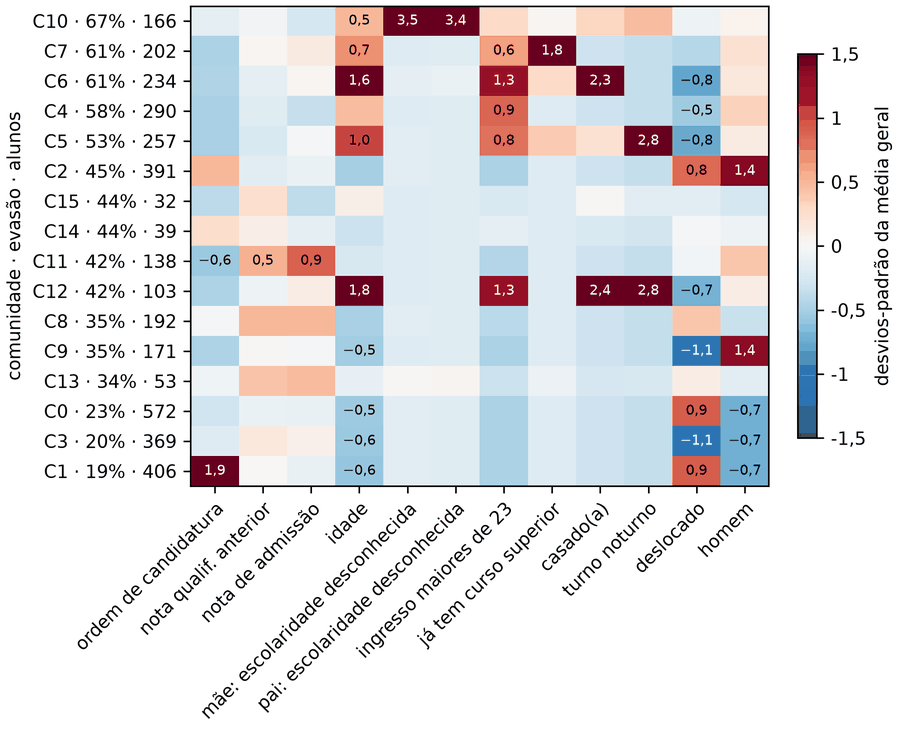

`figuras/04_perfil_3_fim_1sem_gower.pdf`

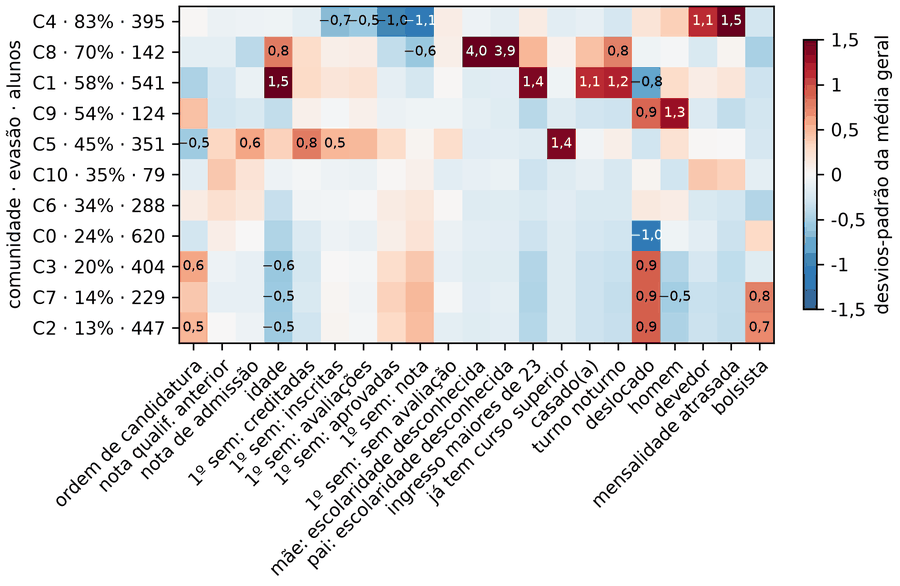

`figuras/04_perfil_3_fim_1sem_associacao.pdf`

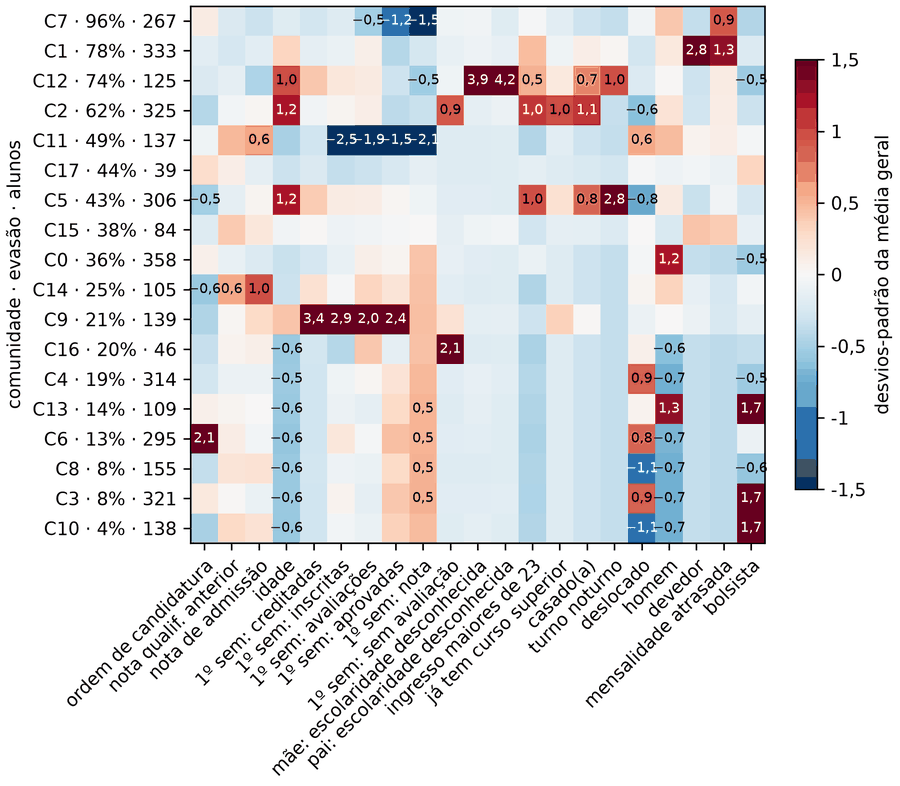

In [15]:
ROT = {"app_order": "ordem de candidatura", "prev_grade": "nota qualif. anterior", "admission_grade": "nota de admissão", "age": "idade",
       "s1_credited": "1º sem: creditadas", "s1_enrolled": "1º sem: inscritas", "s1_evaluations": "1º sem: avaliações",
       "s1_approved": "1º sem: aprovadas", "s1_grade": "1º sem: nota", "s1_without_eval": "1º sem: sem avaliação"}
FLAGS = {"mãe: escolaridade desconhecida": ("mother_qual", 34), "pai: escolaridade desconhecida": ("father_qual", 34),
         "ingresso maiores de 23": ("app_mode", 39), "já tem curso superior": ("app_mode", 7), "casado(a)": ("marital", 2),
         "turno noturno": ("shift", 0), "deslocado": ("displaced", 1), "homem": ("gender", 1),
         "devedor": ("debtor", 1), "mensalidade atrasada": ("tuition_ok", 0), "bolsista": ("scholarship", 1)}

def tabela_perfil(jan):
    cats, nums = JANELAS[jan]
    T = df[nums].rename(columns=ROT).astype(float)
    for nome, (v, val) in FLAGS.items():
        if v in cats: T[nome] = (df[v] == val).astype(float)
    return (T - T.mean()) / T.std()

for jan in JANELAS_RODAR:
    Zp = tabela_perfil(jan)
    for dist in DISTANCIAS:
        r = RES[jan, dist, "Leiden"]; M = Zp.groupby(r["memb"]).mean().loc[r["comp"].index]
        fig, ax = plt.subplots(figsize=(LARGURA, 1.9 + 0.2 * len(M)), layout="constrained")
        im = ax.imshow(M.values, cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
        for (yy, xx), v in np.ndenumerate(M.values):
            if abs(v) >= 0.5: ax.text(xx, yy, f"{v:.1f}".replace(".", ",").replace("-", "−"), ha="center", va="center",
                                      fontsize=7, color="white" if abs(v) > 1 else "black")   # 7 pt: única exceção, 9 pt não cabe na célula
        ax.set_xticks(range(M.shape[1]), M.columns, rotation=45, ha="right", rotation_mode="anchor")
        ax.set_yticks(range(len(M)), [f"C{c} · {e:.0%} · {n}" for c, e, n in zip(M.index, r["comp"].evasao, r["comp"].alunos)])
        ax.set_ylabel("comunidade · evasão · alunos")
        cb = fig.colorbar(im, ax=ax, shrink=0.8, label="desvios-padrão da média geral"); cb.ax.yaxis.set_major_formatter(FMT_BR)
        salva(fig, f"04_perfil_{jan}_{SLUG[dist]}")

Os mesmos perfis em texto (3 comunidades de maior evasão por variação), para citar no artigo:

In [16]:
# quem está nas comunidades de maior risco: numéricas em desvios-padrão da média geral;
# categorias presentes em >= 50% da comunidade e pelo menos 1,3x mais comuns que na base (×lift)
pd.set_option("display.max_colwidth", None)
def perfil(jan, dist, top=3):
    cats, nums = JANELAS[jan]; r = RES[jan, dist, "Leiden"]; z = (df[nums] - df[nums].mean()) / df[nums].std()
    linhas = []
    for c in r["comp"].index[:top]:
        m = r["memb"] == c; zc = z[m].mean(); zc = zc[zc.abs().sort_values(ascending=False).index[:3]]
        dom = []                                   # categorias com >= 50% na comunidade e lift >= 1,3 sobre a base
        for v in cats:
            for val, sh in df.loc[m, v].value_counts(normalize=True).items():
                lift = sh / (df[v] == val).mean()
                if sh >= 0.5 and lift >= 1.3: dom.append((f"{v}={val} ×{lift:.1f}", sh))
        dom = sorted(dom, key=lambda t: -t[1])[:3]
        linhas.append(dict(comunidade=c, alunos=m.sum(), evasao=f"{y[m].mean():.0%}",
                           numericas="; ".join(f"{k} {v:+.1f}dp" for k, v in zc.items()),
                           categorias="; ".join(f"{k} ({v:.0%})" for k, v in dom)))
    return pd.DataFrame(linhas)

for jan in JANELAS_RODAR:
    for dist in DISTANCIAS:
        print(f"\n--- {dist} · {jan}: 3 comunidades de maior evasão"); display(perfil(jan, dist))


--- Gower · 1_matricula: 3 comunidades de maior evasão


,comunidade,alunos,evasao,numericas,categorias
0,9,142,70%,age +0.7dp; admission_grade -0.4dp; app_order -0.1dp,mother_occ=0 ×21.1 (83%); mother_qual=34 ×22.3 (78%); father_qual=34 ×23.7 (71%)
1,0,534,59%,age +1.5dp; app_order -0.5dp; prev_grade -0.3dp,displaced=0 ×1.9 (86%); app_mode=39 ×4.2 (78%); mother_qual=37 ×3.0 (70%)
2,8,161,59%,age +0.9dp; app_order -0.5dp; admission_grade +0.4dp,app_mode=7 ×20.8 (76%); displaced=0 ×1.7 (76%); prev_qual=3 ×18.7 (63%)



--- Associação · 1_matricula: 3 comunidades de maior evasão


,comunidade,alunos,evasao,numericas,categorias
0,10,166,67%,age +0.5dp; admission_grade -0.3dp; app_order -0.1dp,mother_occ=0 ×19.4 (77%); mother_qual=34 ×19.5 (68%); father_qual=34 ×20.3 (61%)
1,7,202,61%,age +0.7dp; app_order -0.5dp; admission_grade +0.1dp,displaced=0 ×1.5 (66%)
2,6,234,61%,age +1.6dp; app_order -0.5dp; prev_grade -0.1dp,displaced=0 ×1.9 (84%); marital=2 ×8.2 (74%); app_mode=39 ×3.7 (68%)



--- Gower · 3_fim_1sem: 3 comunidades de maior evasão


,comunidade,alunos,evasao,numericas,categorias
0,4,395,83%,s1_grade -1.1dp; s1_approved -1.0dp; s1_enrolled -0.7dp,tuition_ok=0 ×4.8 (65%); gender=1 ×1.5 (51%)
1,8,142,70%,age +0.8dp; s1_grade -0.6dp; admission_grade -0.4dp,mother_occ=0 ×20.0 (79%); mother_qual=34 ×21.9 (77%); father_qual=34 ×23.5 (70%)
2,1,541,58%,age +1.5dp; app_order -0.5dp; s1_credited +0.3dp,displaced=0 ×1.9 (86%); mother_qual=37 ×3.2 (74%); father_qual=37 ×2.6 (73%)



--- Associação · 3_fim_1sem: 3 comunidades de maior evasão


,comunidade,alunos,evasao,numericas,categorias
0,7,267,96%,s1_grade -1.5dp; s1_approved -1.2dp; s1_evaluations -0.5dp,gender=1 ×1.6 (54%)
1,1,333,78%,s1_approved -0.4dp; age +0.3dp; s1_grade -0.3dp,debtor=1 ×8.7 (99%); displaced=0 ×1.3 (59%); tuition_ok=0 ×4.3 (58%)
2,12,125,74%,age +1.0dp; s1_grade -0.5dp; admission_grade -0.5dp,scholarship=0 ×1.3 (97%); mother_qual=34 ×21.7 (76%); father_qual=34 ×25.0 (75%)


## 7. Robustez: Gower × Associação

In [17]:
from sklearn.metrics import adjusted_rand_score as ARI
ARIS, CRUZ, frases = {}, {}, []
for jan in JANELAS_RODAR:
    rg, ra = RES[jan, "Gower", "Leiden"], RES[jan, "Associação", "Leiden"]
    ARIS[jan] = ARI(rg["memb"], ra["memb"])
    CRUZ[jan] = pd.crosstab(rg["memb"], ra["memb"], normalize="index").loc[rg["comp"].index, ra["comp"].index]
    topo = CRUZ[jan].iloc[0]                       # comunidade do Gower com mais evasão
    frases.append(f"{ {'1_matricula': 'na', '3_fim_1sem': 'no'}[jan]} {NOME_JAN[jan]}, ARI = {br(ARIS[jan])}; {topo.max():.0%} dos alunos da comunidade de maior "
                  f"evasão do Gower ({rg['comp'].evasao.iloc[0]:.0%}) caem numa única comunidade da Associação "
                  f"({ra['comp'].evasao[topo.idxmax()]:.0%} de evasão)")
display(Markdown("As duas distâncias geram partições diferentes no detalhe, e a figura mostra onde os grupos coincidem: "
                 + "; ".join(frases) + "."))

As duas distâncias geram partições diferentes no detalhe, e a figura mostra onde os grupos coincidem: na matrícula, ARI = 0,33; 95% dos alunos da comunidade de maior evasão do Gower (70%) caem numa única comunidade da Associação (67% de evasão); no fim do 1º semestre, ARI = 0,21; 40% dos alunos da comunidade de maior evasão do Gower (83%) caem numa única comunidade da Associação (78% de evasão).

**Figura 05 — Gower × Associação.** Linhas = comunidades do Gower, colunas = comunidades da Associação, ambas da maior para a menor evasão. A cor mostra que fração de cada comunidade do Gower caiu em cada comunidade da Associação. Um quadrado escuro no canto superior esquerdo quer dizer que as duas distâncias acharam o mesmo grupo de alto risco.

`figuras/05_gower_vs_associacao_1_matricula.pdf`

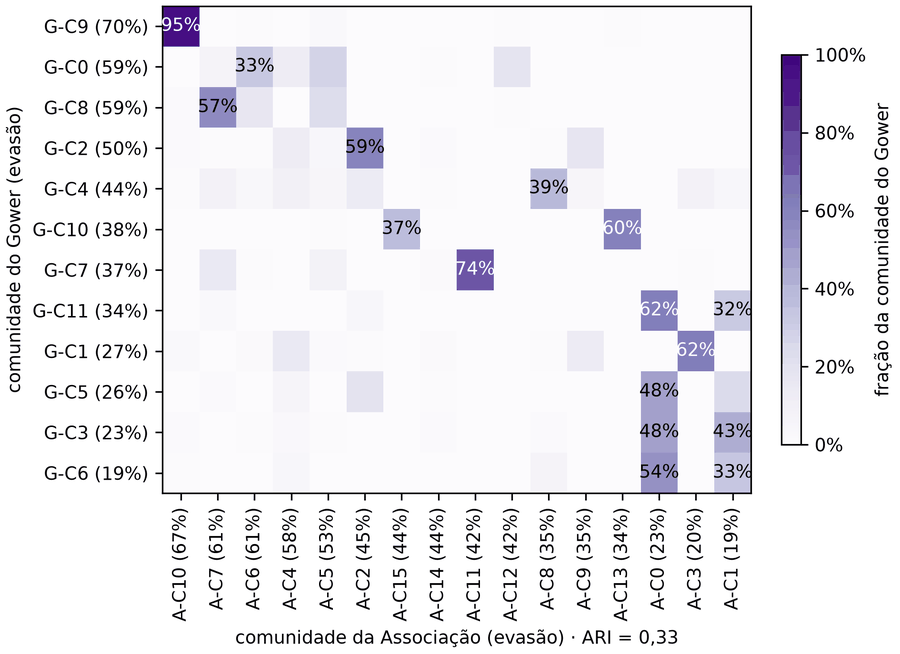

`figuras/05_gower_vs_associacao_3_fim_1sem.pdf`

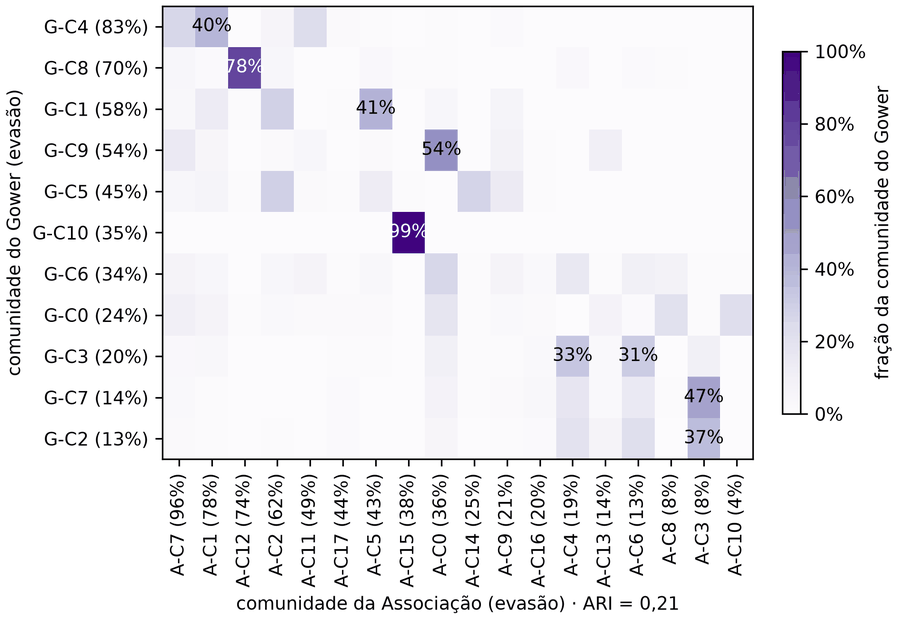

In [18]:
for jan in JANELAS_RODAR:
    rg, ra = RES[jan, "Gower", "Leiden"], RES[jan, "Associação", "Leiden"]; T = CRUZ[jan]
    fig, ax = plt.subplots(figsize=(LARGURA, 1.7 + 0.24 * len(T)), layout="constrained")
    im = ax.imshow(T.values, cmap="Purples", vmin=0, vmax=1, aspect="auto")
    for (yy, xx), v in np.ndenumerate(T.values):
        if v >= 0.3: ax.text(xx, yy, f"{v:.0%}", ha="center", va="center", color="white" if v > 0.6 else "black")
    ax.set_yticks(range(len(T)), [f"G-C{c} ({e:.0%})" for c, e in zip(T.index, rg["comp"].evasao)])
    ax.set_xticks(range(T.shape[1]), [f"A-C{c} ({e:.0%})" for c, e in zip(T.columns, ra["comp"].evasao)], rotation=90)
    ax.set_ylabel("comunidade do Gower (evasão)")
    ax.set_xlabel(f"comunidade da Associação (evasão) · ARI = {br(ARIS[jan])}")
    fig.colorbar(im, ax=ax, shrink=0.8, label="fração da comunidade do Gower", format=PercentFormatter(1))
    salva(fig, f"05_gower_vs_associacao_{jan}")

## 8. Resultados da GNN

In [19]:
f1m = {(j, d): RES[j, d, "GNN"].groupby("modelo").F1.mean() for j in JANELAS_RODAR for d in DISTANCIAS}
ganho = [v["GraphSAGE"] - v["MLP (sem arestas)"] for v in f1m.values()]
f1g = [v["GraphSAGE"] for v in f1m.values()]
sinal = lambda v: f"{v:+.3f}".replace(".", ",").replace("-", "−")
erros = [((RES[j, d, "oof"]["GraphSAGE"] > 0.5).astype(int) != y).mean() for j in JANELAS_RODAR for d in DISTANCIAS]
display(Markdown(
    f"A GraphSAGE chega a F1 entre {br(min(f1g))} e {br(max(f1g))}, mas empata com o mesmo modelo sem arestas: "
    f"o ganho GNN − MLP fica entre {sinal(min(ganho))} e {sinal(max(ganho))}. Fora da dobra, a GNN erra "
    f"de {min(erros):.0%} a {max(erros):.0%} dos alunos."))

A GraphSAGE chega a F1 entre 0,67 e 0,86, mas empata com o mesmo modelo sem arestas: o ganho GNN − MLP fica entre −0,010 e +0,003. Fora da dobra, a GNN erra de 13% a 32% dos alunos.

**Figura 06 — F1 por modelo.** GraphSAGE × mesmo modelo sem arestas × logística. Barras de erro = desvio entre as 5 dobras. Se as barras roxas não ficam acima das cinzas, a vizinhança não ajudou a prever.

`figuras/06_gnn_f1.pdf`

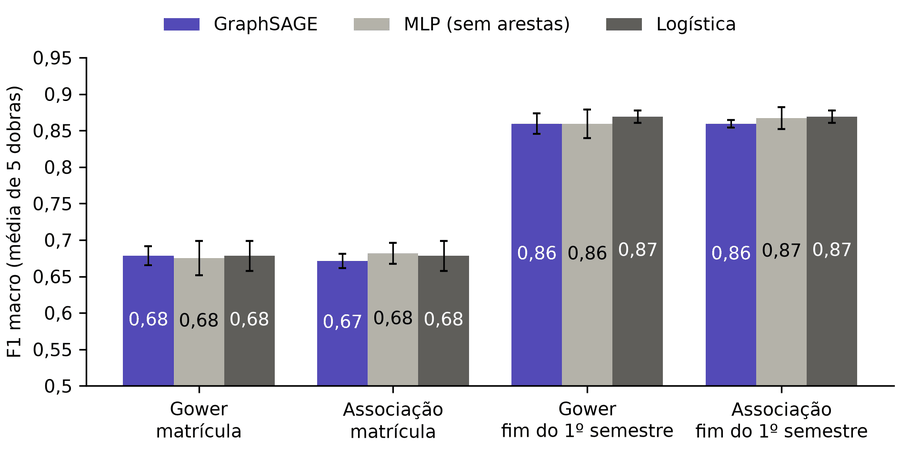

In [20]:
t = pd.concat([RES[j, d, "GNN"].assign(janela=j, distancia=d) for j in JANELAS_RODAR for d in DISTANCIAS])
res_f1 = t.groupby(["janela", "distancia", "modelo"]).F1.agg(["mean", "std"])
grupos = [(j, d) for j in JANELAS_RODAR for d in DISTANCIAS]
x = np.arange(len(grupos)); lg = 0.26
fig, ax = plt.subplots(figsize=(LARGURA, 0.5 * LARGURA), layout="constrained")
for k, m in enumerate(CORES_M):
    sel = res_f1.xs(m, level="modelo").loc[grupos]
    b = ax.bar(x + (k - 1) * lg, sel["mean"], lg, yerr=sel["std"], capsize=2, error_kw=dict(lw=0.8), color=CORES_M[m], label=m)
    ax.bar_label(b, labels=[br(v) for v in sel["mean"]], label_type="center", color="black" if m.startswith("MLP") else "white")
ax.set_xticks(x, [f"{d}\n{NOME_JAN[j]}" for j, d in grupos]); ax.set_ylim(0.5, 0.95)
ax.yaxis.set_major_formatter(FMT_BR); ax.set_ylabel("F1 macro (média de 5 dobras)")
ax.spines[["top", "right"]].set_visible(False)
fig.legend(loc="outside upper center", ncols=3, frameon=False)
salva(fig, "06_gnn_f1")

**Figura 07 — GNN no grafo.** Mesmas posições da figura 01. (a) Risco previsto P(evadiu); cada aluno foi previsto por um modelo que **não** o viu no treino (previsão fora da dobra). (b) Erros em preto. Os erros se concentram onde evadidos e formados se misturam: alunos parecidos com finais diferentes, que nenhum modelo separa com esses dados.

`figuras/07_gnn_grafo_1_matricula_gower.pdf`

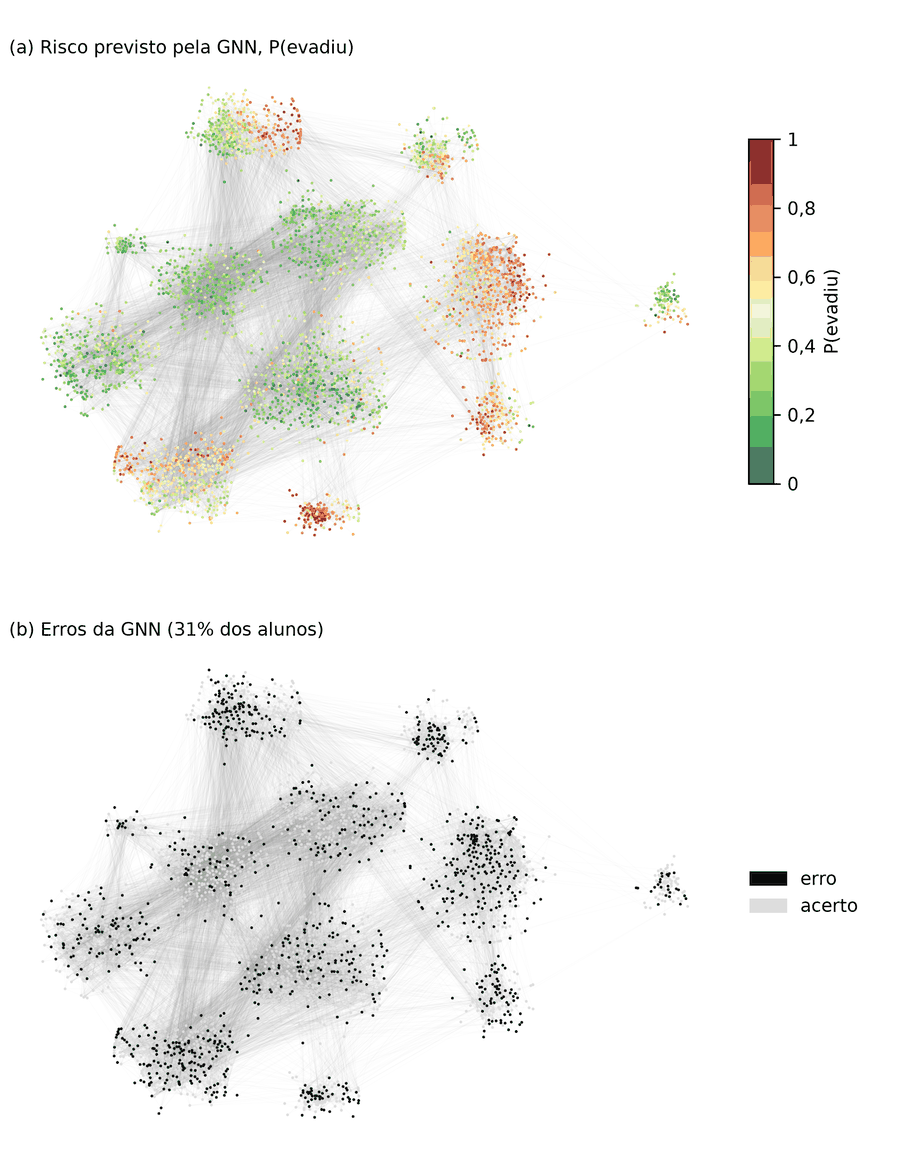

`figuras/07_gnn_grafo_1_matricula_associacao.pdf`

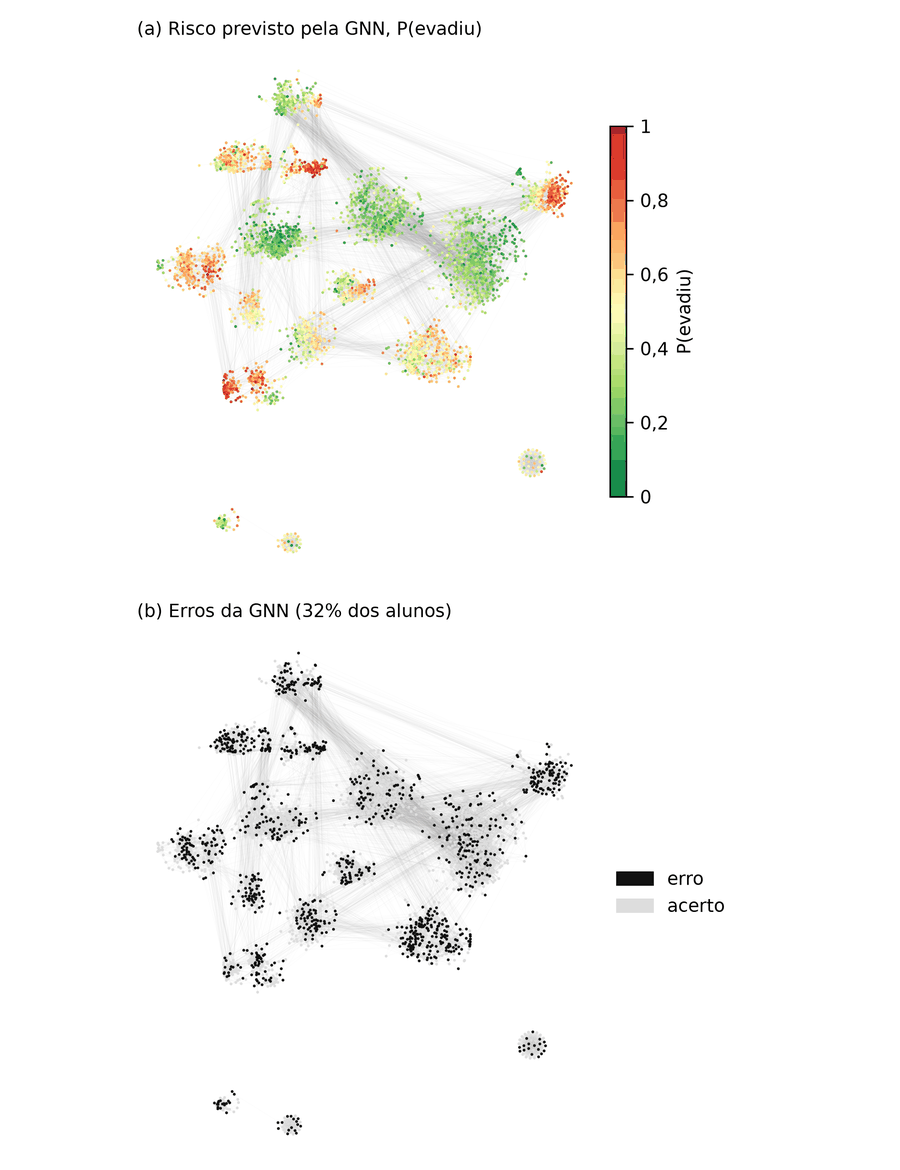

`figuras/07_gnn_grafo_3_fim_1sem_gower.pdf`

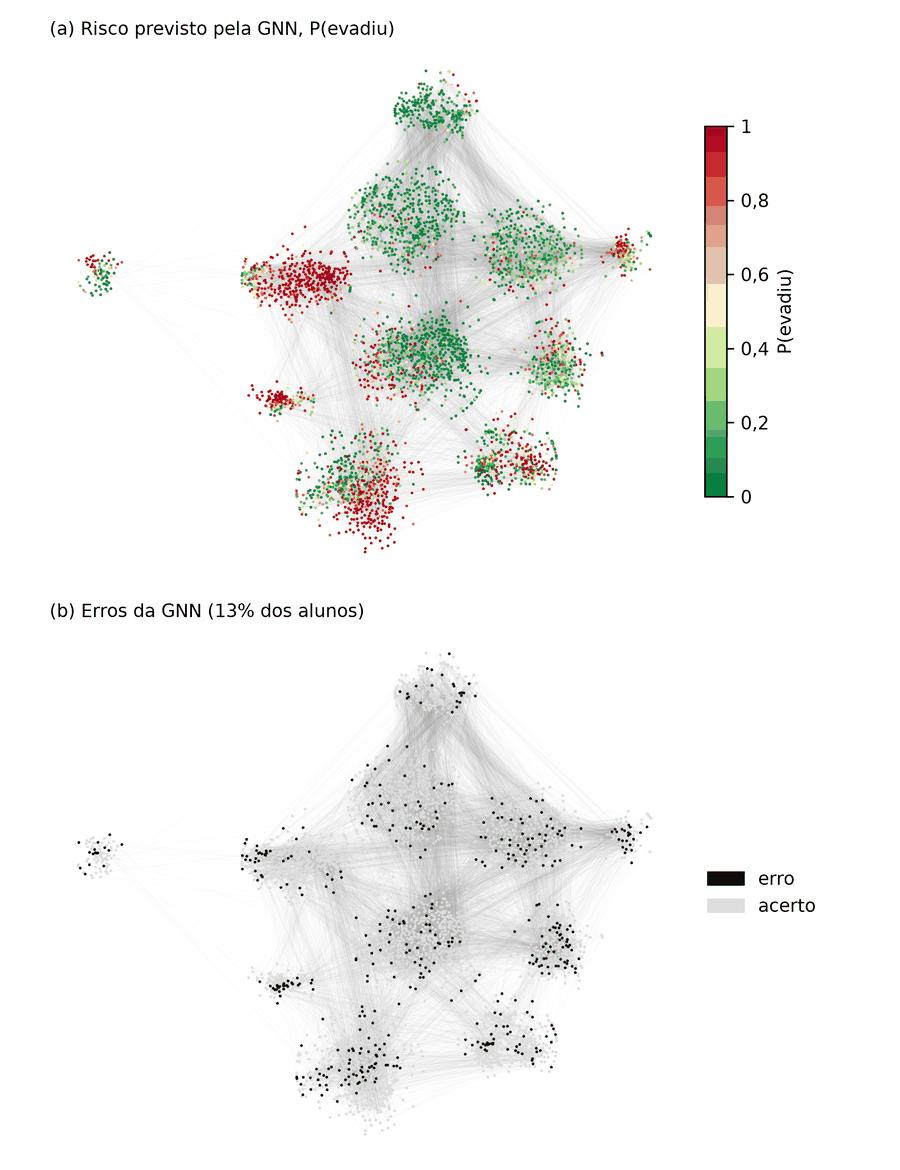

`figuras/07_gnn_grafo_3_fim_1sem_associacao.pdf`

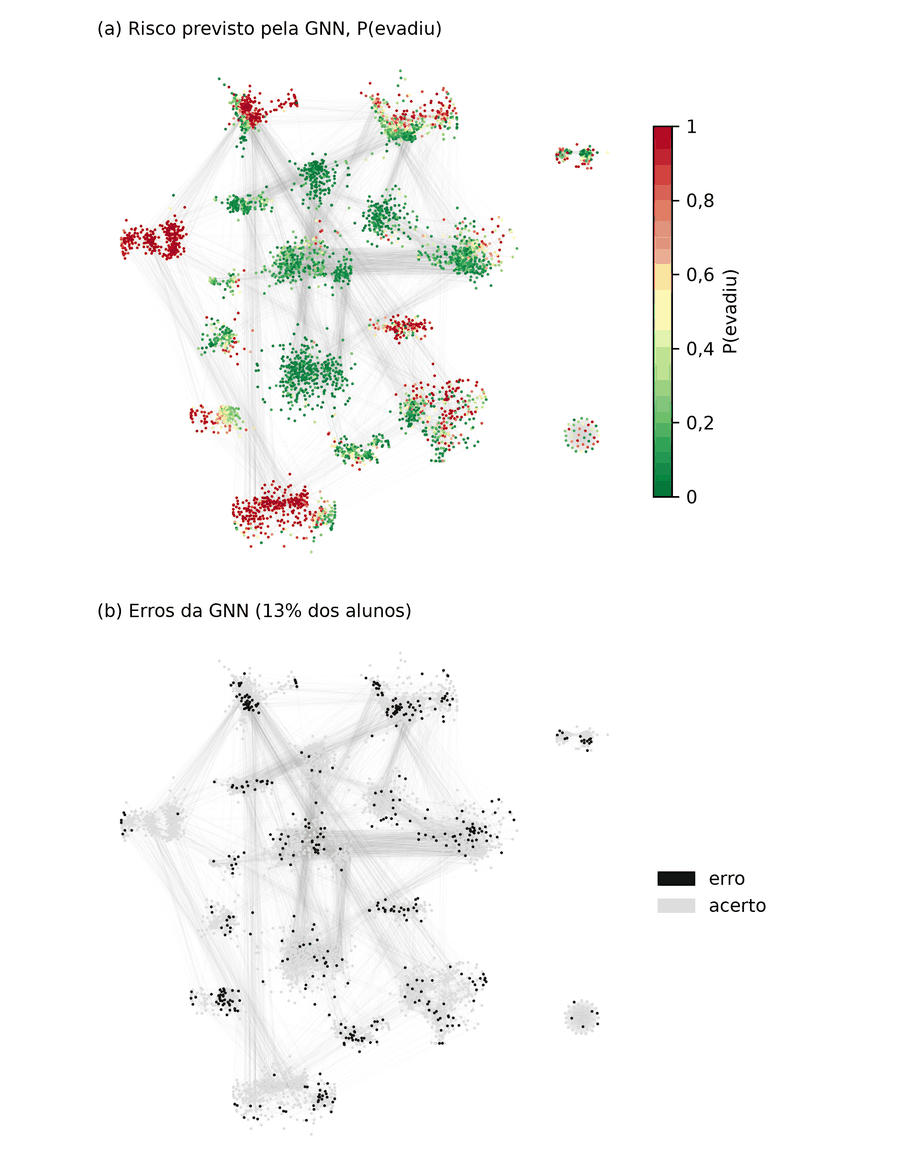

In [21]:
for jan in JANELAS_RODAR:
    for dist in DISTANCIAS:
        p = RES[jan, dist, "oof"]["GraphSAGE"]; erro = (p > 0.5).astype(int) != y
        fig, (a, b) = figura_grafo()
        desenha(a, jan, dist, RISCO(p), "(a) Risco previsto pela GNN, P(evadiu)")
        barra_cor(a, "P(evadiu)")
        desenha(b, jan, dist, None, f"(b) Erros da GNN ({erro.mean():.0%} dos alunos)", s=0)
        pos = posicoes(jan, dist); ordem = np.argsort(erro, kind="stable"); ordem = ordem[~np.isnan(pos[ordem, 0])]   # erros por cima
        b.scatter(pos[ordem, 0], pos[ordem, 1], c=np.where(erro, "#111111", "#dddddd")[ordem], s=S_PONTO, linewidths=0, zorder=2, rasterized=True)
        b.legend(handles=[Patch(color="#111111", label="erro"), Patch(color="#dddddd", label="acerto")],
                 loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
        salva(fig, f"07_gnn_grafo_{jan}_{SLUG[dist]}")

## 9. Como ler

- **Leiden:** um V acima do maior valor obtido com o desfecho embaralhado (p = 0,001 é o menor possível com 1.000 permutações) quer dizer que os perfis são reais: as comunidades têm taxas de evasão diferentes, e o grafo foi montado **sem** o desfecho.
- **GNN:** se o ganho GNN − MLP fica perto de zero, a vizinhança não traz informação nova. Isso é esperado, porque as arestas saem dos mesmos atributos que o modelo já recebe. O objetivo do projeto é **descrever** perfis, não ganhar na previsão.
- **Gower × associação:** se as duas distâncias apontam o mesmo grupo de risco, o achado não depende da escolha da distância.
- Associação não é causa. O perfil de risco serve para oferecer apoio, nunca para rotular o aluno.